# ReviewLens — Sentiment Analysis Experiments

**Author:** Mohammad Alizada 

**Student ID:** 20243120081

**Course:** Professional Training 

**Folder:** `ali081`

Instructor: Professor Ahmad Zahir  

Topic: Mid-term Assignment 

This notebook records the baseline, parameter search, larger-data experiment, and final comparison.


## 1. Python environment




In [ ]:
import sys

print("Python version:", sys.version)
print("Python location:", sys.executable)

Python version: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
Python location: D:\AnacondaD\Anaconda\python.exe


In [ ]:
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import gradio as gr
import joblib

print("All packages imported successfully!")
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Gradio:", gr.__version__)

All packages imported successfully!
Pandas: 2.3.3
Scikit-learn: 1.7.2
Gradio: 6.17.3


## 2. Version 1: UCI Amazon sentences




In [ ]:
from pathlib import Path
from urllib.request import urlopen
from io import BytesIO
import zipfile

project_dir = Path.cwd()

if project_dir.name != "ali081":
    raise RuntimeError("Open the notebook inside PT22026/ali081 first.")

data_dir = project_dir / "data"
data_dir.mkdir(exist_ok=True)

data_file = data_dir / "amazon_cells_labelled.txt"

url = (
    "https://archive.ics.uci.edu/static/public/331/"
    "sentiment%2Blabelled%2Bsentences.zip"
)

if data_file.exists():
    print("Dataset already downloaded:", data_file)
else:
    print("Downloading dataset...")

    with urlopen(url, timeout=60) as response:
        zip_bytes = response.read()

    with zipfile.ZipFile(BytesIO(zip_bytes)) as archive:
        matching_files = [
            name for name in archive.namelist()
            if name.endswith("/amazon_cells_labelled.txt")
            and not name.startswith("__MACOSX/")
        ]

        if len(matching_files) != 1:
            raise RuntimeError("Could not identify the Amazon dataset file.")

        data_file.write_bytes(archive.read(matching_files[0]))

    print("Download completed:", data_file)

Download completed: C:\Users\Mohammad\Desktop\Fith_Semister\Profesional Training\assignment\PT22026\ali081\data\amazon_cells_labelled.txt


In [ ]:
import pandas as pd
import csv

df = pd.read_csv(
    data_file,
    sep="\t",
    header=None,
    names=["review", "label"],
    quoting=csv.QUOTE_NONE,
    encoding="utf-8"
)

print("Dataset shape:", df.shape)
print("\nNumber of reviews per label:")
print(df["label"].value_counts().sort_index())

print("\nMissing values:")
print(df.isna().sum())

print("\nFirst five reviews:")
display(df.head())

Dataset shape: (1000, 2)

Number of reviews per label:
label
0    500
1    500
Name: count, dtype: int64

Missing values:
review    0
label     0
dtype: int64

First five reviews:


,review,label
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1


## 2.1 Data cleaning




In [ ]:
# Keep the original df unchanged.
clean_df = df.dropna(subset=["review", "label"]).copy()

# Remove extra spaces while keeping words and punctuation.
clean_df["review"] = (
    clean_df["review"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

clean_df = clean_df[clean_df["review"] != ""].copy()

# Check that every label is valid.
assert clean_df["label"].isin([0, 1]).all(), "Unexpected label found."
clean_df["label"] = clean_df["label"].astype(int)

# Use lowercase text to detect repeated reviews.
clean_df["review_key"] = clean_df["review"].str.lower()

# Remove reviews that have conflicting labels.
label_counts = clean_df.groupby("review_key")["label"].nunique()
conflicting_keys = label_counts[label_counts > 1].index

conflict_mask = clean_df["review_key"].isin(conflicting_keys)
print("Rows with conflicting labels:", int(conflict_mask.sum()))

clean_df = clean_df[~conflict_mask].copy()

# Keep one copy of each remaining review.
duplicates = clean_df.duplicated(subset="review_key").sum()
print("Repeated rows removed:", int(duplicates))

clean_df = (
    clean_df.drop_duplicates(subset="review_key")
    .reset_index(drop=True)
)

print("Original reviews:", len(df))
print("Reviews after cleaning:", len(clean_df))
print("\nLabels after cleaning:")
print(clean_df["label"].value_counts().sort_index())

Rows with conflicting labels: 0
Repeated rows removed: 13
Original reviews: 1000
Reviews after cleaning: 987

Labels after cleaning:
label
0    496
1    491
Name: count, dtype: int64


## 2.2 Training, validation, and test splits




In [ ]:
from sklearn.model_selection import train_test_split

SEED = 42

# Reserve 30% for validation and testing.
train_df, remaining_df = train_test_split(
    clean_df,
    test_size=0.30,
    random_state=SEED,
    stratify=clean_df["label"]
)

# Divide that 30% into two equal parts.
val_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    random_state=SEED,
    stratify=remaining_df["label"]
)

# Verify that no duplicate review crosses between sets.
train_keys = set(train_df["review_key"])
val_keys = set(val_df["review_key"])
test_keys = set(test_df["review_key"])

assert train_keys.isdisjoint(val_keys)
assert train_keys.isdisjoint(test_keys)
assert val_keys.isdisjoint(test_keys)

summary = pd.DataFrame([
    {
        "Set": name,
        "Reviews": len(part),
        "Negative": int((part["label"] == 0).sum()),
        "Positive": int((part["label"] == 1).sum())
    }
    for name, part in [
        ("Training", train_df),
        ("Validation", val_df),
        ("Test", test_df)
    ]
])

display(summary)
print("Verified: no duplicate reviews shared between sets.")

# Save locally inside the ignored data folder.
for name, part in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    part[["review", "label"]].to_csv(
        data_dir / f"{name}.csv",
        index=False
    )

print("All three datasets saved.")

,Set,Reviews,Negative,Positive
0,Training,690,347,343
1,Validation,148,74,74
2,Test,149,75,74


Verified: no duplicate reviews shared between sets.
All three datasets saved.


## 2.3 Baseline classifiers




In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

models = {
    "Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            stop_words=None
        )),
        ("classifier", MultinomialNB(alpha=1.0))
    ]),

    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            stop_words=None
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ])
}

print("Both model pipelines are ready.")

Both model pipelines are ready.


## 2.4 Validation comparison




In [ ]:
import pandas as pd
from time import perf_counter
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

X_train = train_df["review"]
y_train = train_df["label"]

X_val = val_df["review"]
y_val = val_df["label"]

rows = []

for name, model in models.items():
    start = perf_counter()

    # Learn only from training data.
    model.fit(X_train, y_train)

    training_seconds = perf_counter() - start

    train_predictions = model.predict(X_train)
    val_predictions = model.predict(X_val)

    rows.append({
        "Model": name,
        "Train accuracy": accuracy_score(
            y_train, train_predictions
        ),
        "Validation accuracy": accuracy_score(
            y_val, val_predictions
        ),
        "Macro precision": precision_score(
            y_val, val_predictions,
            average="macro", zero_division=0
        ),
        "Macro recall": recall_score(
            y_val, val_predictions,
            average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_val, val_predictions,
            average="macro", zero_division=0
        ),
        "Training seconds": training_seconds
    })

    print(f"{name}: training completed.")

comparison_df = (
    pd.DataFrame(rows)
    .sort_values(
        ["Macro F1", "Validation accuracy"],
        ascending=False
    )
    .reset_index(drop=True)
)

display(comparison_df.round(4))

results_dir = project_dir / "results"
results_dir.mkdir(exist_ok=True)

comparison_df.to_csv(
    results_dir / "validation_comparison.csv",
    index=False
)

print("Validation results saved.")

Naive Bayes: training completed.
Logistic Regression: training completed.


,Model,Train accuracy,Validation accuracy,Macro precision,Macro recall,Macro F1,Training seconds
0,Naive Bayes,0.9971,0.8243,0.8282,0.8243,0.8238,0.0737
1,Logistic Regression,0.9971,0.8176,0.8190,0.8176,0.8174,0.1839


Validation results saved.


## 2.5 Final baseline evaluation




In [ ]:
from sklearn.base import clone
from sklearn.metrics import classification_report, accuracy_score, f1_score
import joblib
import json

# Select using validation results only.
best_name = comparison_df.iloc[0]["Model"]
final_model = clone(models[best_name])

# Combine training and validation data.
development_df = pd.concat(
    [train_df, val_df],
    ignore_index=True
)

final_model.fit(
    development_df["review"],
    development_df["label"]
)

# Evaluate on the untouched test set.
test_predictions = final_model.predict(test_df["review"])

test_accuracy = accuracy_score(
    test_df["label"], test_predictions
)
test_macro_f1 = f1_score(
    test_df["label"], test_predictions,
    average="macro", zero_division=0
)

print("Selected model:", best_name)
print("Final training reviews:", len(development_df))
print("Test reviews:", len(test_df))
print(f"Test accuracy: {test_accuracy:.2%}")
print(f"Test Macro F1: {test_macro_f1:.4f}")

report_text = classification_report(
    test_df["label"],
    test_predictions,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    digits=4,
    zero_division=0
)

print("\nClassification report:")
print(report_text)

# Save the entire pipeline: TF-IDF + classifier.
models_dir = project_dir / "models"
models_dir.mkdir(exist_ok=True)
results_dir = project_dir / "results"
results_dir.mkdir(exist_ok=True)

joblib.dump(final_model, models_dir / "sentiment_pipeline.joblib")

metrics = {
    "selected_model": best_name,
    "selection_metric": "validation macro F1",
    "final_training_reviews": len(development_df),
    "test_reviews": len(test_df),
    "test_accuracy": float(test_accuracy),
    "test_macro_f1": float(test_macro_f1)
}

(results_dir / "test_metrics.json").write_text(
    json.dumps(metrics, indent=2),
    encoding="utf-8"
)

(results_dir / "test_classification_report.txt").write_text(
    report_text,
    encoding="utf-8"
)

print("Model and test results saved.")

Selected model: Naive Bayes
Final training reviews: 838
Test reviews: 149
Test accuracy: 81.88%
Test Macro F1: 0.8172

Classification report:
              precision    recall  f1-score   support

    Negative     0.9000    0.7200    0.8000        75
    Positive     0.7640    0.9189    0.8344        74

    accuracy                         0.8188       149
   macro avg     0.8320    0.8195    0.8172       149
weighted avg     0.8325    0.8188    0.8171       149

Model and test results saved.


## 2.6 Confusion matrix




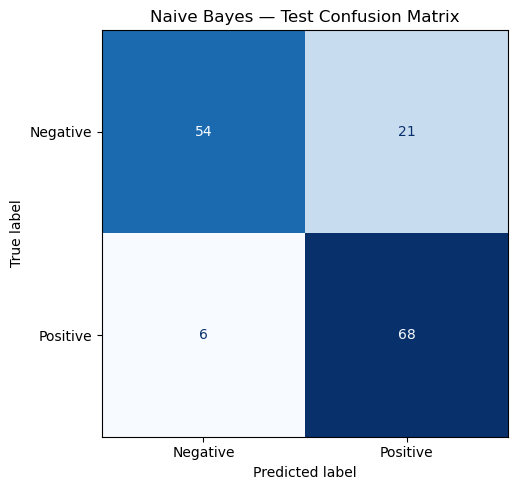

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    test_df["label"],
    test_predictions,
    labels=[0, 1],
    display_labels=["Negative", "Positive"],
    cmap="Blues",
    colorbar=False,
    ax=ax
)

ax.set_title(f"{best_name} — Test Confusion Matrix")
fig.tight_layout()

fig.savefig(
    results_dir / "test_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 2.7 Error inspection




In [ ]:
# Match each test review with its prediction.
test_analysis = test_df[["review", "label"]].copy()
test_analysis["predicted_label"] = test_predictions

sentiment_names = {0: "Negative", 1: "Positive"}

test_analysis["Actual"] = (
    test_analysis["label"].map(sentiment_names)
)
test_analysis["Predicted"] = (
    test_analysis["predicted_label"].map(sentiment_names)
)

mistakes = test_analysis[
    test_analysis["label"] != test_analysis["predicted_label"]
].copy()

print("Total mistakes:", len(mistakes))

# Show examples of both kinds of mistake.
with pd.option_context("display.max_colwidth", None):
    print("\nNegative reviews predicted as positive:")
    display(
        mistakes[mistakes["label"] == 0]
        [["review", "Actual", "Predicted"]]
        .head(5)
    )

    print("\nPositive reviews predicted as negative:")
    display(
        mistakes[mistakes["label"] == 1]
        [["review", "Actual", "Predicted"]]
        .head(5)
    )

# Keep review-level data in the ignored data folder.
mistakes.to_csv(
    data_dir / "test_misclassifications.csv",
    index=False
)

print("Mistakes saved for analysis.")

Total mistakes: 27

Negative reviews predicted as positive:


,review,Actual,Predicted
574,Due to this happening on every call I was forced to stop using this headset.,Negative,Positive
917,Never got it!!!!!,Negative,Positive
669,Can't upload ringtones from a third party.,Negative,Positive
97,I found this product to be waaay too big.,Negative,Positive
542,Trying to make a call on these is an exercise in frustration.,Negative,Positive



Positive reviews predicted as negative:


,review,Actual,Predicted
519,I ended up sliding it on the edge of my pants or back pockets instead.,Positive,Negative
926,"I like the fact that it rests lightly against your ear, rather than inside.",Positive,Negative
889,The cutouts and buttons are placed perfectly.,Positive,Negative
964,":-)Oh, the charger seems to work fine.",Positive,Negative
540,"No shifting, no bubbling, no peeling, not even a scratch, NOTHING!I couldn't be more happier with my new one for the Droid.",Positive,Negative


Mistakes saved for analysis.


## 3. Diagnostic examples

These examples illustrate behavior; they are not a representative test set. Neutral, mixed, and unrelated inputs are outside the binary product-review task.


In [ ]:
from pathlib import Path
import joblib
import pandas as pd

model = joblib.load(
    Path.cwd() / "models" / "sentiment_pipeline.joblib"
)

checks = [
    ("This headset works perfectly. I love it.", "Positive"),
    ("The charger broke after one day. Terrible quality.", "Negative"),
    ("The sound quality is excellent.", "Positive"),
    ("The sound quality is not good.", "Negative"),
    ("I am happy with this purchase.", "Positive"),
    ("I am disappointed with this purchase.", "Negative"),
    ("The phone arrived this morning.", "Neutral / factual"),
    ("The sound is great, but the battery is terrible.", "Mixed"),
    ("This morning, I got a prize.", "Outside product-review scope"),
]

texts = [text for text, expected in checks]
predictions = model.predict(texts)
probabilities = model.predict_proba(texts)

names = {0: "Negative", 1: "Positive"}
class_positions = {
    int(label): position
    for position, label in enumerate(model.classes_)
}

rows = []
for (text, expected), prediction, probs in zip(
    checks, predictions, probabilities
):
    rows.append({
        "Review": text,
        "Expected meaning": expected,
        "Prediction": names[int(prediction)],
        "Positive estimate": round(
            float(probs[class_positions[1]]), 3
        ),
        "Negative estimate": round(
            float(probs[class_positions[0]]), 3
        ),
    })

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(rows))

,Review,Expected meaning,Prediction,Positive estimate,Negative estimate
0,This headset works perfectly. I love it.,Positive,Positive,0.887,0.113
1,The charger broke after one day. Terrible quality.,Negative,Negative,0.250,0.750
2,The sound quality is excellent.,Positive,Positive,0.868,0.132
3,The sound quality is not good.,Negative,Positive,0.573,0.427
4,I am happy with this purchase.,Positive,Positive,0.758,0.242
5,I am disappointed with this purchase.,Negative,Negative,0.357,0.643
6,The phone arrived this morning.,Neutral / factual,Negative,0.488,0.512
7,"The sound is great, but the battery is terrible.",Mixed,Positive,0.544,0.456
8,"This morning, I got a prize.",Outside product-review scope,Positive,0.588,0.412


## 3.1 Parameter search on the original training split

Search 18 settings using five-fold cross-validation. The vectorizer stays inside the pipeline to learn vocabulary within each fold. Evaluate the selected candidate on validation data.


In [ ]:
from pathlib import Path
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score

project_dir = Path.cwd()

if project_dir.name != "ali081":
    raise RuntimeError("Open your notebook inside PT22026/ali081.")

train_data = pd.read_csv(project_dir / "data" / "train.csv")
validation_data = pd.read_csv(
    project_dir / "data" / "validation.csv"
)

pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words=None
    )),
    ("classifier", MultinomialNB())
])

# Try different phrase lengths and classifier settings.
parameter_grid = [
    {
        "tfidf__ngram_range": [(1, 1), (1, 2), (1, 3)],
        "classifier": [MultinomialNB()],
        "classifier__alpha": [0.1, 0.5, 1.0]
    },
    {
        "tfidf__ngram_range": [(1, 1), (1, 2), (1, 3)],
        "classifier": [
            LogisticRegression(max_iter=2000, random_state=42)
        ],
        "classifier__C": [0.5, 2.0, 10.0]
    }
]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search = GridSearchCV(
    estimator=pipeline,
    param_grid=parameter_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=2,
    verbose=1,
    return_train_score=False,
    error_score="raise"
)

print("Comparing 18 settings using 5-fold cross-validation...")

search.fit(
    train_data["review"],
    train_data["label"]
)

print("\nBest settings:")
print(search.best_params_)
print(f"\nBest average CV Macro F1: {search.best_score_:.4f}")

# This candidate is fitted on the training split only.
candidate_model = search.best_estimator_

validation_predictions = candidate_model.predict(
    validation_data["review"]
)

print(
    "\nCandidate validation accuracy:",
    f"{accuracy_score(validation_data['label'], validation_predictions):.2%}"
)

print(
    "Candidate validation Macro F1:",
    f"{f1_score(validation_data['label'], validation_predictions, average='macro'):.4f}"
)

# Show the five strongest settings.
cv_results = pd.DataFrame(search.cv_results_)

display(
    cv_results[
        ["rank_test_score", "mean_test_score",
         "std_test_score", "params"]
    ]
    .sort_values("rank_test_score")
    .head(5)
    .reset_index(drop=True)
)

Comparing 18 settings using 5-fold cross-validation...
Fitting 5 folds for each of 18 candidates, totalling 90 fits

Best settings:
{'classifier': LogisticRegression(max_iter=2000, random_state=42), 'classifier__C': 10.0, 'tfidf__ngram_range': (1, 2)}

Best average CV Macro F1: 0.8201

Candidate validation accuracy: 81.76%
Candidate validation Macro F1: 0.8174


,rank_test_score,mean_test_score,std_test_score,params
0,1,0.820104,0.032298,{'classifier': LogisticRegression(max_iter=200...
1,2,0.814158,0.033842,{'classifier': LogisticRegression(max_iter=200...
2,3,0.811149,0.043147,{'classifier': LogisticRegression(max_iter=200...
3,4,0.808236,0.030955,{'classifier': LogisticRegression(max_iter=200...
4,5,0.803791,0.044449,{'classifier': LogisticRegression(max_iter=200...


## 4. Version 2: larger Amazon Polarity sample

Take 20,000 reviews from the official training split with a seeded shuffle buffer. Buffered sampling is not a uniform shuffle of the entire dataset.


In [ ]:
from pathlib import Path
from datasets import load_dataset
import pandas as pd

project_dir = Path.cwd()

if project_dir.name != "ali081":
    raise RuntimeError("Open the notebook inside PT22026/ali081.")

data_dir = project_dir / "data"
data_dir.mkdir(exist_ok=True)

sample_path = data_dir / "amazon_polarity_v2_raw.csv"

if sample_path.exists():
    larger_df = pd.read_csv(sample_path)
    print("Loaded the existing sample.")

else:
    print("Connecting to Amazon Polarity...", flush=True)

    stream = load_dataset(
        "fancyzhx/amazon_polarity",
        split="train",
        streaming=True
    )

    stream = stream.shuffle(seed=42, buffer_size=10000)

    rows = []

    # Download only a sample from the official training split.
    # Leave the official test split unused.
    for item in stream.take(20000):
        rows.append({
            "review": item["content"],
            "label": int(item["label"])
        })

        if len(rows) % 2000 == 0:
            print(f"Loaded {len(rows):,} reviews...", flush=True)

    larger_df = pd.DataFrame(rows)

    if len(larger_df) != 20000:
        raise RuntimeError(
            f"Expected 20,000 reviews, received {len(larger_df)}."
        )

    larger_df.to_csv(sample_path, index=False)
    print("Sample saved.")

print("\nDataset shape:", larger_df.shape)

print("\nLabel counts: 0 = Negative, 1 = Positive")
print(larger_df["label"].value_counts().sort_index())

print("\nMissing values:")
print(larger_df.isna().sum())

display(larger_df.head(3))

Connecting to Amazon Polarity...


README.md:   0%|          | 0.00/6.81k [00:00<?, ?B/s]

C:\Users\Mohammad\AppData\Roaming\Python\Python313\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Mohammad\.cache\huggingface\hub\datasets--fancyzhx--amazon_polarity. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Loaded 2,000 reviews...
Loaded 4,000 reviews...
Loaded 6,000 reviews...
Loaded 8,000 reviews...
Loaded 10,000 reviews...
Loaded 12,000 reviews...
Loaded 14,000 reviews...
Loaded 16,000 reviews...
Loaded 18,000 reviews...
Loaded 20,000 reviews...
Sample saved.

Dataset shape: (20000, 2)

Label counts: 0 = Negative, 1 = Positive
label
0    10138
1     9862
Name: count, dtype: int64

Missing values:
review    0
label     0
dtype: int64


,review,label
0,I bought three packs of these disks. They are ...,0
1,"At 60 pages,this is over-priced and not a cour...",0
2,We ordered this boe bot after my son used a ve...,0


## 4.1 Remove duplicates and conflicting labels




In [ ]:
from pathlib import Path
import pandas as pd

project_dir = Path.cwd()

if project_dir.name != "ali081":
    raise RuntimeError("Open the notebook inside PT22026/ali081.")

data_dir = project_dir / "data"

raw_v2 = pd.read_csv(data_dir / "amazon_polarity_v2_raw.csv")
clean_v2 = raw_v2.dropna(subset=["review", "label"]).copy()

# Normalize whitespace, preserving punctuation and words like "not".
clean_v2["review"] = (
    clean_v2["review"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

clean_v2 = clean_v2[clean_v2["review"] != ""].copy()

if not clean_v2["label"].isin([0, 1]).all():
    raise ValueError("Unexpected labels found.")

clean_v2["label"] = clean_v2["label"].astype(int)

# Detect duplicates regardless of capitalization.
clean_v2["review_key"] = clean_v2["review"].str.casefold()

# Remove all copies of reviews with contradictory labels.
label_counts = clean_v2.groupby("review_key")["label"].nunique()
conflicting_keys = label_counts[label_counts > 1].index

conflict_mask = clean_v2["review_key"].isin(conflicting_keys)
print("Rows with conflicting labels:", int(conflict_mask.sum()))

clean_v2 = clean_v2.loc[~conflict_mask].copy()

duplicate_count = clean_v2.duplicated("review_key").sum()
print("Duplicate rows removed:", int(duplicate_count))

clean_v2 = (
    clean_v2.drop_duplicates("review_key")
    .reset_index(drop=True)
)

print("Original reviews:", len(raw_v2))
print("Clean reviews:", len(clean_v2))

Rows with conflicting labels: 0
Duplicate rows removed: 7
Original reviews: 20000
Clean reviews: 19993


## 4.2 Stratified development splits




In [ ]:
from sklearn.model_selection import train_test_split

train_v2, val_v2 = train_test_split(
    clean_v2,
    test_size=0.20,
    random_state=42,
    stratify=clean_v2["label"]
)

# Check that identical normalized reviews cannot cross the split.
assert set(train_v2["review_key"]).isdisjoint(
    set(val_v2["review_key"])
)

summary_v2 = pd.DataFrame([
    {
        "Set": name,
        "Reviews": len(part),
        "Negative": int((part["label"] == 0).sum()),
        "Positive": int((part["label"] == 1).sum())
    }
    for name, part in [
        ("Training", train_v2),
        ("Validation", val_v2)
    ]
])

display(summary_v2)

# Separate filenames preserve the original experiment.
train_v2.to_csv(data_dir / "train_v2.csv", index=False)
val_v2.to_csv(data_dir / "validation_v2.csv", index=False)

print("Version 2 splits saved.")
print("Verified: no identical normalized reviews shared between sets.")

,Set,Reviews,Negative,Positive
0,Training,15994,8105,7889
1,Validation,3999,2026,1973


Version 2 splits saved.
Verified: no identical normalized reviews shared between sets.


## 4.3 Candidate comparison




In [ ]:
from pathlib import Path
from time import perf_counter

import pandas as pd
import joblib

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

project_dir = Path.cwd()

if project_dir.name != "ali081":
    raise RuntimeError("Open the notebook inside PT22026/ali081.")

train_v2 = pd.read_csv(project_dir / "data" / "train_v2.csv")
val_v2 = pd.read_csv(project_dir / "data" / "validation_v2.csv")

results_dir = project_dir / "results"
models_dir = project_dir / "models"

results_dir.mkdir(exist_ok=True)
models_dir.mkdir(exist_ok=True)


def make_pipeline(classifier):
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            stop_words=None,
            min_df=2,
            max_features=100000,
            sublinear_tf=True
        )),
        ("classifier", classifier)
    ])


models_v2 = {
    "Naive Bayes": make_pipeline(
        MultinomialNB(alpha=0.5)
    ),
    "Logistic Regression": make_pipeline(
        LogisticRegression(
            C=10.0,
            solver="liblinear",
            max_iter=2000,
            random_state=42
        )
    )
}

rows = []

for name, model in models_v2.items():
    print(f"Training {name}...", flush=True)
    start = perf_counter()

    # Vocabulary and model are learned from training reviews only.
    model.fit(train_v2["review"], train_v2["label"])

    training_seconds = perf_counter() - start

    train_predictions = model.predict(train_v2["review"])
    val_predictions = model.predict(val_v2["review"])

    rows.append({
        "Model": name,
        "Train accuracy": accuracy_score(
            train_v2["label"], train_predictions
        ),
        "Validation accuracy": accuracy_score(
            val_v2["label"], val_predictions
        ),
        "Macro precision": precision_score(
            val_v2["label"], val_predictions,
            average="macro", zero_division=0
        ),
        "Macro recall": recall_score(
            val_v2["label"], val_predictions,
            average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            val_v2["label"], val_predictions,
            average="macro", zero_division=0
        ),
        "Training seconds": training_seconds
    })

    print(f"Completed in {training_seconds:.1f} seconds.\n")


comparison_v2 = (
    pd.DataFrame(rows)
    .sort_values(
        ["Macro F1", "Validation accuracy"],
        ascending=False
    )
    .reset_index(drop=True)
)

display(comparison_v2.round(4))

comparison_v2.to_csv(
    results_dir / "validation_comparison_v2.csv",
    index=False
)

# Save a candidate separately from the original app model.
best_name_v2 = comparison_v2.iloc[0]["Model"]
candidate_v2 = models_v2[best_name_v2]

joblib.dump(
    candidate_v2,
    models_dir / "sentiment_v2_candidate.joblib"
)

print("Selected candidate:", best_name_v2)
print("Version 2 candidate and validation results saved.")
print("Your original app model remains unchanged.")

Training Naive Bayes...
Completed in 4.6 seconds.

Training Logistic Regression...
Completed in 4.3 seconds.



,Model,Train accuracy,Validation accuracy,Macro precision,Macro recall,Macro F1,Training seconds
0,Logistic Regression,0.9987,0.8800,0.8800,0.8799,0.8799,4.3367
1,Naive Bayes,0.9640,0.8615,0.8624,0.8611,0.8613,4.6398


Selected candidate: Logistic Regression
Version 2 candidate and validation results saved.
Your original app model remains unchanged.


## 4.4 Refit the selected candidate




In [ ]:
from pathlib import Path
import pandas as pd
import joblib
from sklearn.base import clone

project_dir = Path.cwd()

if project_dir.name != "ali081":
    raise RuntimeError("Open the notebook inside PT22026/ali081.")

data_dir = project_dir / "data"
models_dir = project_dir / "models"
results_dir = project_dir / "results"
results_dir.mkdir(exist_ok=True)

train_v2 = pd.read_csv(data_dir / "train_v2.csv")
val_v2 = pd.read_csv(data_dir / "validation_v2.csv")

development_v2 = pd.concat(
    [train_v2, val_v2], ignore_index=True
)

candidate_v2 = joblib.load(
    models_dir / "sentiment_v2_candidate.joblib"
)

final_v2 = clone(candidate_v2)

print("Training final version 2 model...", flush=True)

final_v2.fit(
    development_v2["review"],
    development_v2["label"]
)

joblib.dump(
    final_v2,
    models_dir / "sentiment_pipeline_v2.joblib"
)

print("Training reviews:", len(development_v2))
print("Saved: sentiment_pipeline_v2.joblib")

Training final version 2 model...
Training reviews: 19993
Saved: sentiment_pipeline_v2.joblib


## 5. Independent test sample and overlap checks

Use the official test split and remove normalized exact matches against development data and the earlier UCI test set. This check does not exclude every possible near-duplicate.


In [ ]:
from datasets import load_dataset

raw_test_path = data_dir / "amazon_test_v2_raw.csv"

if raw_test_path.exists():
    raw_test_v2 = pd.read_csv(raw_test_path)
    print("Loaded saved test sample.")
else:
    print("Downloading test sample...", flush=True)

    test_stream = load_dataset(
        "fancyzhx/amazon_polarity",
        split="test",
        streaming=True
    ).shuffle(seed=123, buffer_size=10000)

    rows = []
    for item in test_stream.take(5000):
        rows.append({
            "review": item["content"],
            "label": int(item["label"])
        })

        if len(rows) % 1000 == 0:
            print(f"Loaded {len(rows):,} reviews...", flush=True)

    raw_test_v2 = pd.DataFrame(rows)

    if len(raw_test_v2) != 5000:
        raise RuntimeError("The test sample download was incomplete.")

    raw_test_v2.to_csv(raw_test_path, index=False)


def normalize_reviews(series):
    return (
        series.fillna("")
        .astype(str)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
        .str.casefold()
    )


# Exclude all previously used review texts, including the old test set.
known_keys = set(normalize_reviews(development_v2["review"]))

for filename in ["train.csv", "validation.csv", "test.csv"]:
    old_data = pd.read_csv(data_dir / filename)
    known_keys.update(normalize_reviews(old_data["review"]))

test_v2 = raw_test_v2.dropna(
    subset=["review", "label"]
).copy()

assert test_v2["label"].isin([0, 1]).all()

test_v2["review_key"] = normalize_reviews(test_v2["review"])
test_v2 = test_v2[test_v2["review_key"] != ""].copy()

label_counts = test_v2.groupby("review_key")["label"].nunique()
conflicts = label_counts[label_counts > 1].index

test_v2 = test_v2[
    ~test_v2["review_key"].isin(conflicts)
].drop_duplicates("review_key")

overlap = test_v2["review_key"].isin(known_keys)
print("Previously seen review texts excluded:", int(overlap.sum()))

test_v2 = test_v2.loc[~overlap].reset_index(drop=True)

assert set(test_v2["review_key"]).isdisjoint(known_keys)
assert test_v2["label"].nunique() == 2

test_v2.to_csv(data_dir / "test_v2.csv", index=False)

print("Final test reviews:", len(test_v2))
print(test_v2["label"].value_counts().sort_index())

Loaded 1,000 reviews...
Loaded 2,000 reviews...
Loaded 3,000 reviews...
Loaded 4,000 reviews...
Loaded 5,000 reviews...
Previously seen review texts excluded: 0
Final test reviews: 5000
label
0    2416
1    2584
Name: count, dtype: int64


## 5.1 Compare both model versions

Both training data and classifier changed. The improvement cannot be attributed to the classifier alone. Do not use this test sample to choose further model settings.


,Model,Test reviews,Test accuracy,Test Macro F1
0,Version 1 — original Naive Bayes,5000,0.7086,0.7055
1,Version 2 — Logistic Regression,5000,0.8756,0.8754



Version 2 classification report:

              precision    recall  f1-score   support

    Negative     0.8766    0.8642    0.8704      2416
    Positive     0.8747    0.8862    0.8804      2584

    accuracy                         0.8756      5000
   macro avg     0.8756    0.8752    0.8754      5000
weighted avg     0.8756    0.8756    0.8756      5000



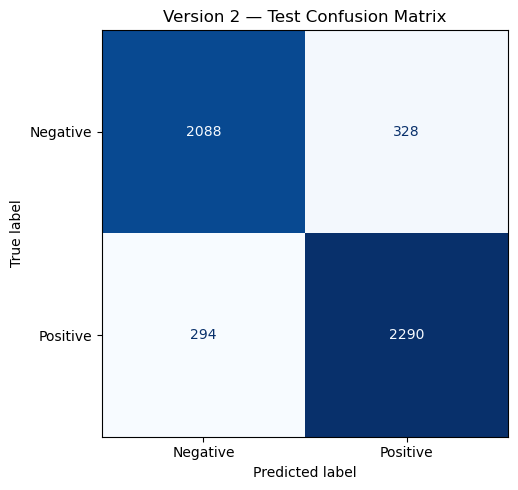

Test results saved.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

original_model = joblib.load(
    models_dir / "sentiment_pipeline.joblib"
)

evaluation_models = {
    "Version 1 — original Naive Bayes": original_model,
    "Version 2 — Logistic Regression": final_v2
}

test_rows = []

for name, model in evaluation_models.items():
    predictions = model.predict(test_v2["review"])

    test_rows.append({
        "Model": name,
        "Test reviews": len(test_v2),
        "Test accuracy": accuracy_score(
            test_v2["label"], predictions
        ),
        "Test Macro F1": f1_score(
            test_v2["label"], predictions,
            average="macro", zero_division=0
        )
    })

test_comparison = pd.DataFrame(test_rows)
display(test_comparison.round(4))

test_comparison.to_csv(
    results_dir / "test_comparison_v2.csv",
    index=False
)

predictions_v2 = final_v2.predict(test_v2["review"])

report_v2 = classification_report(
    test_v2["label"],
    predictions_v2,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    digits=4,
    zero_division=0
)

print("\nVersion 2 classification report:\n")
print(report_v2)

(results_dir / "test_classification_report_v2.txt").write_text(
    report_v2, encoding="utf-8"
)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    test_v2["label"],
    predictions_v2,
    labels=[0, 1],
    display_labels=["Negative", "Positive"],
    cmap="Blues",
    colorbar=False,
    ax=ax
)

ax.set_title("Version 2 — Test Confusion Matrix")
fig.tight_layout()

fig.savefig(
    results_dir / "test_confusion_matrix_v2.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
print("Test results saved.")

## 6. Optional reproduction check


In [ ]:
from pathlib import Path

required = [Path("models/sentiment_pipeline_v2.joblib"), Path("models/sentiment_pipeline_v2_reproduced.joblib"), Path("data/test_v2.csv")]
missing = [str(p) for p in required if not p.exists()]
if missing:
    print("Optional comparison skipped. Missing:", ", ".join(missing))
else:
    from pathlib import Path
    import joblib
    import pandas as pd
    import numpy as np
    
    project_dir = Path.cwd()
    
    original = joblib.load(
        project_dir / "models" / "sentiment_pipeline_v2.joblib"
    )
    reproduced = joblib.load(
        project_dir / "models" / "sentiment_pipeline_v2_reproduced.joblib"
    )
    
    test_data = pd.read_csv(project_dir / "data" / "test_v2.csv")
    
    original_predictions = original.predict(test_data["review"])
    reproduced_predictions = reproduced.predict(test_data["review"])
    
    agreement = np.mean(
        original_predictions == reproduced_predictions
    )
    
    print(f"Prediction agreement: {agreement:.2%}")
    print(
        "Matching predictions:",
        int((original_predictions == reproduced_predictions).sum()),
        "of",
        len(test_data)
    )


Prediction agreement: 100.00%
Matching predictions: 5000 of 5000


## 7. Results and limitations

On the recorded common test sample of 5,000 reviews, the original Naive Bayes model achieved **70.86% accuracy** and version 2 Logistic Regression achieved **87.56% accuracy**, with **0.8754 macro F1**. The accuracy difference is **16.70 percentage points**.

The earlier 81.88% baseline accuracy used a different, smaller UCI test set and is not directly comparable. The version 2 training/validation gap suggests overfitting remains a concern.

- The model has only positive and negative classes; it cannot reliably identify neutral, mixed, or out-of-scope text.
- Probability estimates are not guarantees. The app's 60% uncertainty threshold is a display rule, not a calibrated confidence threshold.
- Negation, sarcasm, and unfamiliar wording can still cause mistakes.
- Prediction agreement on this sample does not establish identical model bytes or identical predictions for all possible inputs.

## 8. Application and maintenance

Maintain the existing `app_v2.py`, `train_v2.py`, `requirements.txt`, and `README.md` separately. Old notebook cells that cloned repositories, made commits, generated files, patched application code, or launched Gradio have been removed from this experiment notebook.

Keep both versions' evaluation results as development evidence. Keep data and trained models excluded from Git. After a meaningful change, test it, review the diff, stage the intended files, and commit from the terminal or VS Code Source Control. Push with `git push fork ali081-work`.
